# 06_other_journals: Other journals (ASTMH, Frontiers, Elsevier Heliyon, Wiley/Hindawi)

Publishers that contribute one or two datasets each; found through Europe PMC.

**How the journal datasets were found.** Europe PMC was searched for every open-access paper with supplementary files whose title/abstract mentions Toxoplasma, toxoplasmosis, gondii, TORCH, multiplex serology or pathogen burden (3,482 papers). Their data files (xlsx, xls, csv, sav, dta, ...) were downloaded from the PMC Open Access S3 bucket (1,407 papers had data files, 6.6 GB) and every table with >= 80 rows was scanned for a Toxoplasma result column (607 tables, 285 papers). Human, participant-level tables with at least two IgG classes were then checked by hand. Scripts: `datasets/_harvest/`.

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

**Sections:** setup → helpers → one section per dataset (where it comes from, how the label is coded, what is removed) → build and evaluate → chart. Outputs are written to `raw/`, `processed/`, `results.csv`, `DATASETS.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/06_other_journals'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


**Notes on this source.** Other journals (one folder because each contributes one or two datasets): Am J Trop Med Hyg (ASTMH), Frontiers,
Elsevier (Heliyon), Wiley/Hindawi (J Parasitol Res) - participant-level supplementary files.

## Helpers (curated loaders and source-specific functions)

In [2]:
import external_datasets as ex

## Datasets

Each cell adds one dataset to `CONFIG`: `source` = where the raw file comes from, `label` / `pos` / `neg` = how the Toxoplasma IgG result is coded, `drop` = extra columns removed (leakage, identifiers, outcomes), `loader` = a hand-written loader in `scripts/` for datasets curated earlier.

In [3]:
CONFIG = []

### thai_myanmar_border_pregnant

**T. gondii in refugee and migrant pregnant women, Thailand-Myanmar border**  
Thailand/Myanmar · Refugee and migrant pregnant women · DOI/ID: `10.4269/ajtmh.16-0999`

Am J Trop Med Hyg.

In [4]:
CONFIG.append(dict(key='thai_myanmar_border_pregnant', title='T. gondii in refugee and migrant pregnant women, Thailand-Myanmar border',
     doi='10.4269/ajtmh.16-0999', setting='Refugee and migrant pregnant women', country='Thailand/Myanmar',
     source=('pmc', 'PMC5508912'), file='tpmd160999.SD1.xlsx', loader=ex.thai_border_pregnant, note='Am J Trop Med Hyg.'))

### brazil_homeless

**Serosurvey of anti-T. gondii antibodies in homeless persons of São Paulo**  
Brazil · Homeless adults in shelters · DOI/ID: `10.3389/fpubh.2020.580637`

Frontiers in Public Health.

In [5]:
CONFIG.append(dict(key='brazil_homeless', title='Serosurvey of anti-T. gondii antibodies in homeless persons of São Paulo',
     doi='10.3389/fpubh.2020.580637', setting='Homeless adults in shelters', country='Brazil',
     source=('pmc', 'PMC7674916'), file='Table_1.xlsx', loader=ex.brazil_homeless, note='Frontiers in Public Health.'))

### colombia_quindio_ocular

**High frequency of ocular toxoplasmosis in Quindío and related risk factors**  
Colombia · Community survey with fundoscopy · DOI/ID: `10.1016/j.heliyon.2021.e06659`

Heliyon (Elsevier). Water, undercooked meat, cats, unwashed vegetables, education, SISBEN poverty level.

In [6]:
CONFIG.append(dict(key='colombia_quindio_ocular', title='High frequency of ocular toxoplasmosis in Quindío and related risk factors',
     doi='10.1016/j.heliyon.2021.e06659', setting='Community survey with fundoscopy', country='Colombia',
     source=('pmc', 'PMC8056222'), file='mmc1.xls', label='IgG Toxo Cualitative', pos=['pos'], neg=['neg'],
     drop=['Code', 'Ocular lesion at fundoscopy?', 'IgM Cualitative result'],
     note='Heliyon (Elsevier). Water, undercooked meat, cats, unwashed vegetables, education, SISBEN poverty level.'))

### iran_psychiatric_inpatients

**Seroepidemiology of T. gondii in psychiatric inpatients and healthy controls, north Iran**  
Iran · Psychiatric inpatients + healthy controls · DOI/ID: `PMC13662829 (J Parasitol Res, 2026)`

Journal of Parasitology Research (Wiley/Hindawi). Cat and soil contact, raw vegetables, vegetable washing + blood count.

In [7]:
CONFIG.append(dict(key='iran_psychiatric_inpatients', title='Seroepidemiology of T. gondii in psychiatric inpatients and healthy controls, north Iran',
     doi='PMC13662829 (J Parasitol Res, 2026)', setting='Psychiatric inpatients + healthy controls', country='Iran',
     source=('pmc', 'PMC13662829'), file='JAPR-2026-2530719-s002.xlsx', label='IgG_toxo', pos=['positive'], neg=['negative'],
     drop=['participant_id'], note='Journal of Parasitology Research (Wiley/Hindawi). Cat and soil contact, raw vegetables, vegetable washing + blood count.'))

## Build and evaluate

Downloads (or copies) each raw file into `raw/`, builds `processed/<dataset>.csv`, removes leakage columns, then runs logistic regression, random forest and XGBoost with 5-fold x 3 cross-validation.

In [8]:
res = run(HERE, CONFIG)

thai_myanmar_border_pregnant       n=   199 pos=   62 feats= 18 best AUC=0.584 (RandomForest)


brazil_homeless                    n=   120 pos=   43 feats= 43 best AUC=0.51 (LogReg)


colombia_quindio_ocular            n=   161 pos=  112 feats= 17 best AUC=0.651 (LogReg)


iran_psychiatric_inpatients        n=   200 pos=   86 feats= 43 best AUC=0.702 (XGBoost)


In [9]:
cols = ['dataset', 'country', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,country,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,thai_myanmar_border_pregnant,Thailand/Myanmar,199,62,0.312,18,0.506,0.584,0.532,0.584,RandomForest
1,brazil_homeless,Brazil,120,43,0.358,43,0.510,0.378,0.390,0.510,LogReg
2,colombia_quindio_ocular,Colombia,161,112,0.696,17,0.651,0.621,0.590,0.651,LogReg
3,iran_psychiatric_inpatients,Iran,200,86,0.430,43,0.683,0.702,0.702,0.702,XGBoost


## Chart

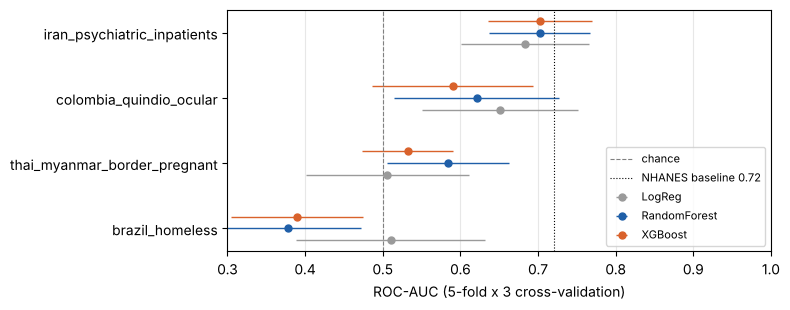

In [10]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()

## What was removed as leakage, and the inputs used

In [11]:
res[['dataset', 'removed_as_leakage', 'features']]

,dataset,removed_as_leakage,features
0,thai_myanmar_border_pregnant,,"age, Migrant/refugee, Gravidity, Parity, Primigravida, P..."
1,brazil_homeless,,"age, 3.Sex, 4.Marital Status, 5.Racial self-declaration,..."
2,colombia_quindio_ocular,"IgM Toxo Absorbance, IgG ( (UI/mL)","Commune, Gender, Age, Do you drink water only bottled or..."
3,iran_psychiatric_inpatients,IgM_toxo,"group, age, sex, age_stratum_5y, dsm5_category, dsm5_sub..."
